Alcoholism and Religious Beliefs + Practices

In [84]:
import pandas as pd
import numpy as np
import plotnine as p9
import warnings
warnings.filterwarnings('ignore')

In [85]:
df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

# 1 = any illegal drug use, 0 = none
df["drug_use"] = np.where(df["V79"].isna(), np.nan, (df["V79"] > 0).astype(int))

print(df["drug_use"].value_counts(dropna=False))   # expect 3221 zeros, 230 ones, 79 missing

drug_use
0.0    3221
1.0     230
NaN      79
Name: count, dtype: int64


In [86]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant", "V41": "bible_complete_guide_to_morality", "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once"
})

In [87]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Load fresh data and rename
df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    # Section A: religious practices
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self", 
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    # Section B: religious beliefs
    "V30": "god_close", "V39": "bible_inerrant", "V41": "bible_complete_guide_to_morality",
    # Outcome ingredient
    "V74": "drink_freq",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# 2. Dependent variable: 1 = drinks more than 30 times a month (code 4), 0 = codes 0-3
df["more_than_30_drinks_monthly"] = np.where(df["drink_freq"].isna(), np.nan,
                                             (df["drink_freq"] == 4).astype(int))
print(df["more_than_30_drinks_monthly"].value_counts(dropna=False))

# 3. Independent variables
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant", "bible_complete_guide_to_morality"]

# 4. One common sample
ca = df[["more_than_30_drinks_monthly"] + practices + beliefs].dropna().copy()
print("N =", len(ca), "| more_than_30_drinks_monthly = 1:", int(ca["more_than_30_drinks_monthly"].sum()))

# 5. Logit
m_alc = smf.logit("more_than_30_drinks_monthly ~ " + " + ".join(practices + beliefs), data=ca).fit()
print(m_alc.summary())

# Odds ratios are easier to explain than raw coefficients
print(np.exp(m_alc.params).round(3))

more_than_30_drinks_monthly
0.0    3302
1.0     146
NaN      82
Name: count, dtype: int64
N = 2984 | more_than_30_drinks_monthly = 1: 111
Optimization terminated successfully.
         Current function value: 0.151357
         Iterations 8
                                Logit Regression Results                               
Dep. Variable:     more_than_30_drinks_monthly   No. Observations:                 2984
Model:                                   Logit   Df Residuals:                     2974
Method:                                    MLE   Df Model:                            9
Date:                         Tue, 17 Nov 2026   Pseudo R-squ.:                 0.04768
Time:                                 17:00:32   Log-Likelihood:                -451.65
converged:                                True   LL-Null:                       -474.26
Covariance Type:                     nonrobust   LLR p-value:                 8.370e-07
                                       coef    std err  

In [88]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant",
    # ALCOHOLISM!!!
    "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# Alcoholic = 1 if ANY of: drinks 30+ times a month, binged in past month, binged in past week
# V75/V76 codes: 1 = Yes, 2 = No, 3 = Uncertain (Uncertain counts as not yes)
outcome_items = ["drink_freq", "month_more_than_5_drinks_at_once", "week_more_than_5_drinks_at_once"]
any_missing = df[outcome_items].isna().any(axis=1)

alcoholic = ((df["drink_freq"] == 4) |
             (df["month_more_than_5_drinks_at_once"] == 1) |
             (df["week_more_than_5_drinks_at_once"] == 1))
df["alcoholic"] = np.where(any_missing, np.nan, alcoholic.astype(int))
print(df["alcoholic"].value_counts(dropna=False))

practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant"]

ca = df[["alcoholic"] + practices + beliefs].dropna().copy()
print("N =", len(ca), "| alcoholic = 1:", int(ca["alcoholic"].sum()))

m_alc = smf.logit("alcoholic ~ " + " + ".join(practices + beliefs), data=ca).fit()
print(m_alc.summary())
print(np.exp(m_alc.params).round(3))

alcoholic
1.0    1681
0.0    1603
NaN     246
Name: count, dtype: int64
N = 2859 | alcoholic = 1: 1409
Optimization terminated successfully.
         Current function value: 0.644098
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              alcoholic   No. Observations:                 2859
Model:                          Logit   Df Residuals:                     2850
Method:                           MLE   Df Model:                            8
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.07063
Time:                        17:00:32   Log-Likelihood:                -1841.5
converged:                       True   LL-Null:                       -1981.4
Covariance Type:            nonrobust   LLR p-value:                 7.843e-56
                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

In [89]:


data_path = next(
    (p for p in matches if "religion_logit" in str(p).lower()),
    matches[0],
)
print(f"Loaded file: {data_path}\n")

# convert_categoricals=False keeps underlying numeric codes from stata (.dta)
raw_df = pd.read_stata(data_path, convert_categoricals=False)

# prep variables
var_map = {
    # religious practices
    "V25": "pray_freq",
    "V26": "table_grace",
    "V27": "pray_self",
    "V28": "pray_close",
    "V29": "pray_others",
    "V34": "attend_services",
    # religious beliefs
    "V30": "god_close",
    "V39": "bible_inerrant",
    "V41": "bible_complete_guide_to_morality",
}

df = raw_df[list(var_map.keys())].rename(columns=var_map).copy()
cols = list(var_map.values())

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

work = df.dropna(subset=cols).copy()
print(f"Complete cases retained: {len(work)} of {len(df)}\n")
print("=== Summary Statistics ===")
print(work[cols].describe().round(2))

# normalise varibles -- scale (mean 0, SD 1) and fit PCA
X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

pc_names = [f"PC{i}" for i in range(1, len(cols) + 1)]
prop = pca.explained_variance_ratio_

variance_table = pd.DataFrame(
    {
        "Standard deviation": pca.explained_variance_ ** 0.5,
        "Proportion of variance": prop,
        "Cumulative proportion": prop.cumsum(),
    },
    index=pc_names,
).T.round(3)

Loaded file: /Users/ricep0et/Documents/hs4002_ay26/religion project/chrisu.DTA

Complete cases retained: 3034 of 3530

=== Summary Statistics ===
       pray_freq  table_grace  pray_self  pray_close  pray_others  \
count    3034.00      3034.00    3034.00      3034.0      3034.00   
mean        2.40         1.43       2.01         2.1         1.62   
std         1.67         1.22       1.38         1.4         1.29   
min         0.00         0.00       0.00         0.0         0.00   
25%         1.00         1.00       1.00         1.0         1.00   
50%         3.00         1.00       2.00         2.0         1.00   
75%         4.00         2.00       3.00         4.0         2.00   
max         5.00         4.00       4.00         4.0         4.00   

       attend_services  god_close  bible_inerrant  \
count          3034.00    3034.00         3034.00   
mean              2.65       2.49            3.03   
std               1.82       1.19            1.45   
min               0.

In [90]:
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant", "bible_complete_guide_to_morality"]

In [122]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from stargazer.stargazer import Stargazer

df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant",
    "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once", "V41": "bible_complete_guide_to_morality",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# separate binary outcomes (missing stays missing)
def flag(col, condition):
    return np.where(df[col].isna(), np.nan, condition.astype(int))

df["drinks_30_plus"] = flag("drink_freq", df["drink_freq"] == 4)                                     # more than 30 times a month
df["binge_month"]    = flag("month_more_than_5_drinks_at_once", df["month_more_than_5_drinks_at_once"] == 1)   # 1 = Yes
df["binge_week"]     = flag("week_more_than_5_drinks_at_once", df["week_more_than_5_drinks_at_once"] == 1)     # 1 = Yes
df["alcoholic"]      = np.where(df[["drinks_30_plus", "binge_month", "binge_week"]].isna().any(axis=1), np.nan,
                                df[["drinks_30_plus", "binge_month", "binge_week"]].max(axis=1))   # any of the three

outcomes = ["alcoholic", "drinks_30_plus", "binge_month", "binge_week"]
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant", "bible_complete_guide_to_morality"]

# 1 common sample
ca = df[outcomes + practices + beliefs].dropna().copy()
print("N =", len(ca))
print(ca[outcomes].mean().round(3))             # share coded 1 for each outcome

# 1 logit per outcome, same predictors
models = [smf.logit(f"{o} ~ " + " + ".join(practices + beliefs), data=ca).fit(disp=0) for o in outcomes]

# table
sg = Stargazer(models)
sg.dependent_variable_name("Alcohol Use")
sg.custom_columns(["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"],
                  [1, 1, 1, 1])
sg.covariate_order(practices + beliefs + ["Intercept"])
sg.rename_covariates({
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "bible_complete_guide_to_morality": "BELIEFS: The Bible is the Complete Guide to Morality",
    "Intercept": "Intercept",
})
sg.add_custom_notes(["Standard errors in parentheses."])
sg

N = 2843
alcoholic         0.492
drinks_30_plus    0.039
binge_month       0.484
binge_week        0.298
dtype: float64


FIGURE 5

In [92]:
# Items are on different scales (0-4, 0-5, 1-5), so standardise each one first (mean 0, SD 1)
z = (ca[practices + beliefs] - ca[practices + beliefs].mean()) / ca[practices + beliefs].std()

ca["practice_index"]    = z[practices].mean(axis=1)              # average of the 6 practices
ca["belief_index"]      = z[beliefs].mean(axis=1)                # average of the 2 beliefs
ca["religiosity_index"] = z[practices + beliefs].mean(axis=1)    # all 8 combined

# Cronbach's alpha: do the items measure one thing? (0.7+ is acceptable, 0.8+ is good)
def cronbach_alpha(items):
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var().sum() / items.sum(axis=1).var())

print("alpha, practices:  ", round(cronbach_alpha(z[practices]), 3))
print("alpha, beliefs:    ", round(cronbach_alpha(z[beliefs]), 3))
print("alpha, all 8 items:", round(cronbach_alpha(z[practices + beliefs]), 3))
print("r(practice_index, belief_index) =", round(ca["practice_index"].corr(ca["belief_index"]), 2))

# Model A: one combined religiosity index, for each outcome
models_a = [smf.logit(f"{o} ~ religiosity_index", data=ca).fit(disp=0) for o in outcomes]
# Model B: practices and beliefs as two separate indices, for each outcome
models_b = [smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0) for o in outcomes]

col_names = ["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"]

sg_a = Stargazer(models_a)
sg_a.dependent_variable_name("Alcohol Use")
sg_a.custom_columns(col_names, [1, 1, 1, 1])
sg_a.rename_covariates({"religiosity_index": "Religiosity Index (all 8 items)"})
sg_a.add_custom_notes(["Index = mean of standardised items. Standard errors in parentheses."])
display(sg_a)

sg_b = Stargazer(models_b)
sg_b.dependent_variable_name("Alcohol Use")
sg_b.custom_columns(col_names, [1, 1, 1, 1])
sg_b.rename_covariates({"practice_index": "PRACTICES Index (6 items)", "belief_index": "BELIEFS Index (3 items)"})
sg_b.add_custom_notes(["Index = mean of standardised items. Standard errors in parentheses."])
display(sg_b)

alpha, practices:   0.902
alpha, beliefs:     0.831
alpha, all 8 items: 0.919
r(practice_index, belief_index) = 0.72


WITH CONTROLS

In [ ]:
# Average marginal effects (AME), WITH demographic controls 
d = cc.copy()
z = (d[practices + beliefs] - d[practices + beliefs].mean()) / d[practices + beliefs].std()
d["practice_index"] = z[practices].mean(axis=1)
d["belief_index"]   = z[beliefs].mean(axis=1)
ctrl = " + ".join(controls) + " + C(university)"
print("N =", len(d))

item_labels["bible_complete_guide_to_morality"] = "The Bible is the Complete Guide to Morality"   # V41 label
item_labels["bible_as_complete_moral_code"] = "The Bible is the Complete Guide to Morality"

def ame_table(formula_rhs, names):
    rows = []
    for o in outcomes:
        m = smf.logit(f"{o} ~ {formula_rhs} + {ctrl}", data=d).fit(disp=0, maxiter=200)
        if not m.mle_retvals["converged"]:
            print(f"  Warning: {outcome_labels[o]} did not converge, so treat that column with caution")
        me = m.get_margeff(at="overall").summary_frame()
        for v in names:
            rows.append({"outcome": outcome_labels[o], "variable": names[v], "AME": me.loc[v, "dy/dx"],
                         "p": me.loc[v, "Pr(>|z|)"]})
    return pd.DataFrame(rows)

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def to_wide(t, order):
    t = t.assign(cell=(t["AME"] * 100).round(1).astype(str) + t["p"].map(stars))
    return t.pivot(index="variable", columns="outcome", values="cell").loc[order, list(outcome_labels.values())]

# Table 1: individual items
item_names = {v: item_labels[v] for v in practices + beliefs}
ame_items_c = ame_table(" + ".join(practices + beliefs), item_names)
print("Average marginal effects, percentage points (item model, with controls)")
display(to_wide(ame_items_c, list(item_names.values())))

# Table 2: practices index vs beliefs index
index_names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)"}
ame_idx_c = ame_table("practice_index + belief_index", index_names)
print("Average marginal effects, percentage points (index model, with controls)")
display(to_wide(ame_idx_c, list(index_names.values())))

N = 2733
Average marginal effects, percentage points (item model, with controls)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
Praying frequency,-3.3***,-1.5***,-3.2***,-2.9***
Saying grace,-5.1***,0.3,-5.5***,-2.8***
Praying for self,-1.7,0.5,-1.9*,0.8
Praying for close people,2.9**,-0.1,3.1**,0.6
Praying for others,-0.2,0.6,-0.3,1.5
Attending services,-2.4***,-0.8**,-2.2***,-1.8***
Closeness to God,2.3**,0.8*,2.2**,1.1
Bible inerrancy,-0.5,0.1,-0.2,-0.9
The Bible is the Complete Guide to Morality,0.6,0.0,0.6,-0.4


Average marginal effects, percentage points (index model, with controls)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
Practices index (per 1 SD),-11.3***,-1.4*,-11.4***,-4.8***
Beliefs index (per 1 SD),0.3,0.3,0.8,-2.6*


In [127]:
# Make sure closeness to God is reversed (higher = closer to God), no matter how many times earlier cells ran
raw_v30 = pd.read_stata("chrisu.DTA", convert_categoricals=False, columns=["V30"])["V30"]
ca["god_close"] = 6 - raw_v30.loc[ca.index]          # V30: 1 = Very close ... 5 = No closeness -> now 5 = Very close

# Check: every item should correlate positively with praying frequency
check = ca[practices + beliefs].corr()["pray_freq"].round(2)
print(check)
assert (check > 0).all(), "An item points the wrong way, check its coding"

pray_freq                           1.00
table_grace                         0.60
pray_self                           0.75
pray_close                          0.71
pray_others                         0.62
attend_services                     0.68
god_close                           0.70
bible_inerrant                      0.56
bible_complete_guide_to_morality    0.54
Name: pray_freq, dtype: float64


In [94]:
m_alone = smf.logit("alcoholic ~ god_close", data=ca).fit(disp=0)          # no controls
m_full  = smf.logit("alcoholic ~ " + " + ".join(practices + beliefs), data=ca).fit(disp=0)   # controls for everything

sg2 = Stargazer([m_alone, m_full])
sg2.custom_columns(["Closeness Only", "With Practices & Beliefs"], [1, 1])
sg2.covariate_order(["god_close"] + practices + ["bible_inerrant", "bible_complete_guide_to_morality", "Intercept"])
sg2

In [123]:
import plotnine as p9

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
outcome_labels = {"alcoholic": "Any heavy drinking", "drinks_30_plus": "Drinks 30+ times a month",
                  "binge_month": "Binged in past month", "binge_week": "Binged in past week"}
item_labels = {"pray_freq": "Praying frequency", "table_grace": "Saying grace", "pray_self": "Praying for self",
               "pray_close": "Praying for close people", "pray_others": "Praying for others",
               "attend_services": "Attending services", "god_close": "Closeness to God", "bible_inerrant": "Bible inerrancy", "bible_complete_guide_to_morality": "The Bible is the Complete Guide to Morality"}
base_theme = (p9.theme_minimal(base_size=11)
              + p9.theme(panel_grid_minor=p9.element_blank(), panel_grid_major_y=p9.element_blank(),
                         plot_title=p9.element_text(weight="bold", ha="left"), axis_text=p9.element_text(color=MUTED)))

MARGINAL EFFECTS!!!! 

In [135]:
# Average marginal effects (AME): change in the PROBABILITY of the outcome for a 1-unit increase,
# averaged over every student in the sample
def ame_table(formula_rhs, names):
    rows = []
    for o in outcomes:
        m = smf.logit(f"{o} ~ {formula_rhs}", data=ca).fit(disp=0)
        me = m.get_margeff(at="overall").summary_frame()
        for v in me.index:
            rows.append({"outcome": outcome_labels[o], "variable": names.get(v, v), "AME": me.loc[v, "dy/dx"],
                         "lo": me.loc[v, "Conf. Int. Low"], "hi": me.loc[v, "Cont. Int. Hi."], "p": me.loc[v, "Pr(>|z|)"]})
    return pd.DataFrame(rows)

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def to_wide(t):
    # Percentage points with stars, one column per outcome (like stargazer)
    t = t.assign(cell=(t["AME"] * 100).round(1).astype(str) + t["p"].map(stars))
    return t.pivot(index="variable", columns="outcome", values="cell")[list(outcome_labels.values())]

# Table 1: full 8-variable model
ame_full = ame_table(" + ".join(practices + beliefs), item_labels)
print("Average marginal effects, percentage points (full model)")
display(to_wide(ame_full).loc[[item_labels[v] for v in practices + beliefs]])

# Table 2: practices index vs beliefs index
index_names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)"}
ame_idx = ame_table("practice_index + belief_index", index_names)
print("Average marginal effects, percentage points (index model)")
display(to_wide(ame_idx).loc[list(index_names.values())])

# Chart: marginal effects of the two indices
ame_idx["outcome"] = pd.Categorical(ame_idx["outcome"], categories=list(outcome_labels.values())[::-1])
ame_idx["variable"] = pd.Categorical(ame_idx["variable"], categories=list(index_names.values()))
chart_me = (p9.ggplot(ame_idx, p9.aes(x="AME", y="outcome", color="variable"))
            + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
            + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
            + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
            + p9.scale_x_continuous(labels=lambda l: [f"{v*100:+.0f} pp" for v in l])
            + p9.scale_color_manual(values={index_names["practice_index"]: BLUE, index_names["belief_index"]: ORANGE})
            + p9.labs(title="More religious practice means a lower chance of heavy drinking",
                      x="Average marginal effect (percentage points) · left of 0 = less drinking", y="", color="")
            + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart_me

Average marginal effects, percentage points (full model)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
PRACTICES: Praying frequency,-4.2***,-1.4***,-3.8***,-3.4***
PRACTICES: Saying grace,-5.6***,0.3,-6.0***,-3.1***
PRACTICES: Praying for self,-2.6**,0.2,-3.0**,-0.1
PRACTICES: Praying for close people,2.4**,-0.2,2.7**,-0.0
PRACTICES: Praying for others,0.3,0.6,0.2,1.8*
PRACTICES: Attending services,-3.6***,-1.0***,-3.4***,-2.7***
BELIEFS: Closeness to God,4.3***,1.1**,4.2***,2.8***
BELIEFS: Bible inerrancy,-0.3,0.1,0.1,-1.1
BELIEFS: The Bible is the Complete Guide to Morality,-0.0,0.1,-0.1,-0.6


PatsyError: Error evaluating factor: NameError: name 'practice_index' is not defined
    alcoholic ~ practice_index + belief_index
                ^^^^^^^^^^^^^^

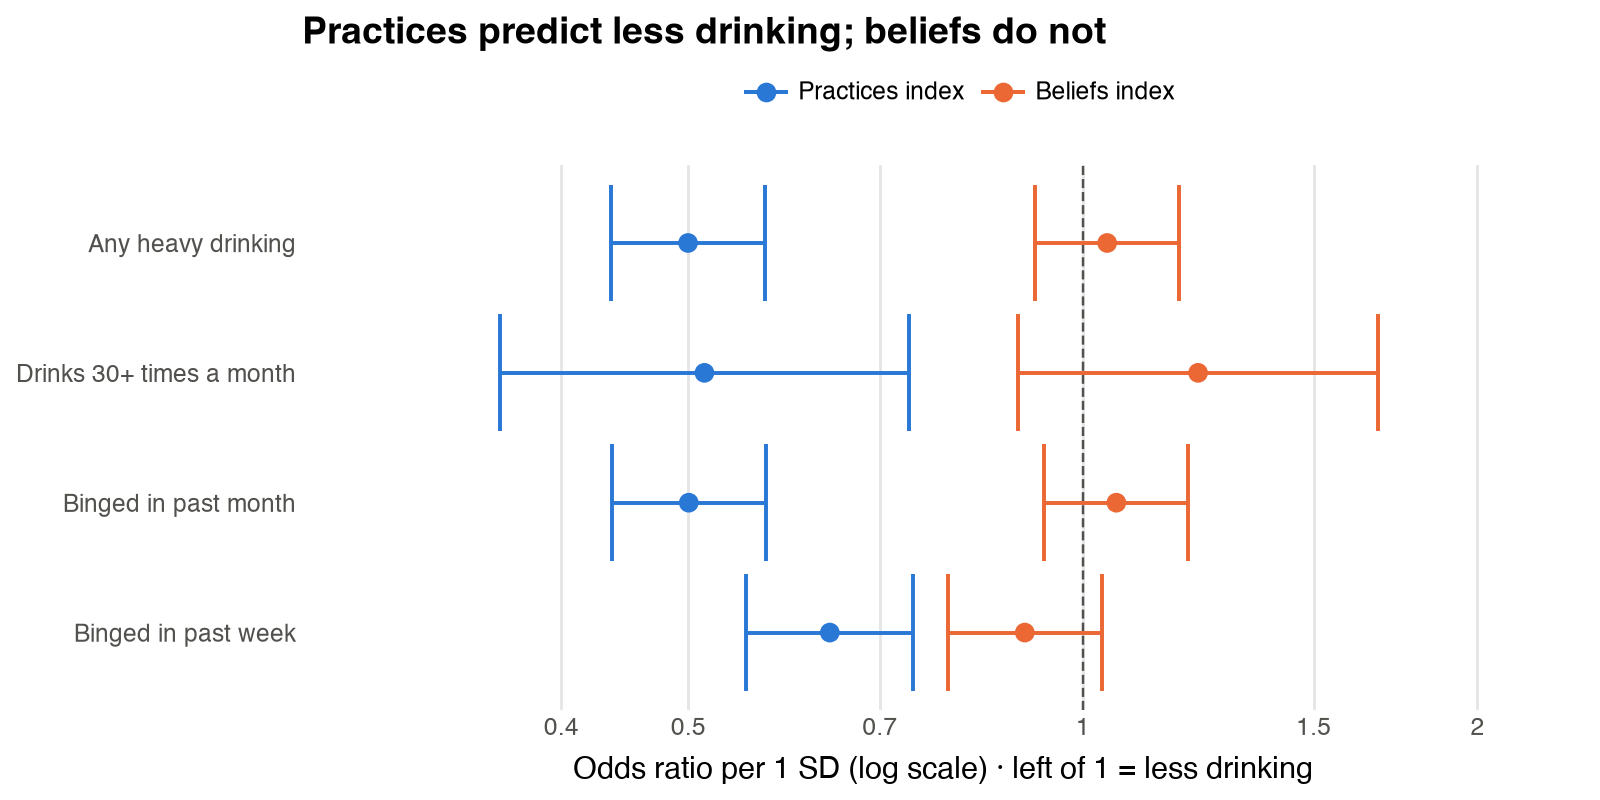

In [97]:
rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0)
    ci = m.conf_int()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab, "OR": np.exp(m.params[v]),
                     "lo": np.exp(ci.loc[v, 0]), "hi": np.exp(ci.loc[v, 1])})
forest = pd.DataFrame(rows)
forest["outcome"] = pd.Categorical(forest["outcome"], categories=list(outcome_labels.values())[::-1])
forest["predictor"] = pd.Categorical(forest["predictor"], categories=["Practices index", "Beliefs index"])
chart1 = (p9.ggplot(forest, p9.aes(x="OR", y="outcome", color="predictor"))
          + p9.geom_vline(xintercept=1, color=MUTED, linetype="dashed")
          + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
          + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
          + p9.scale_x_log10(breaks=[0.4, 0.5, 0.7, 1, 1.5, 2])
          + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
          + p9.labs(title="Practices predict less drinking; beliefs do not",
                    x="Odds ratio per 1 SD (log scale) · left of 1 = less drinking", y="", color="")
          + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart1

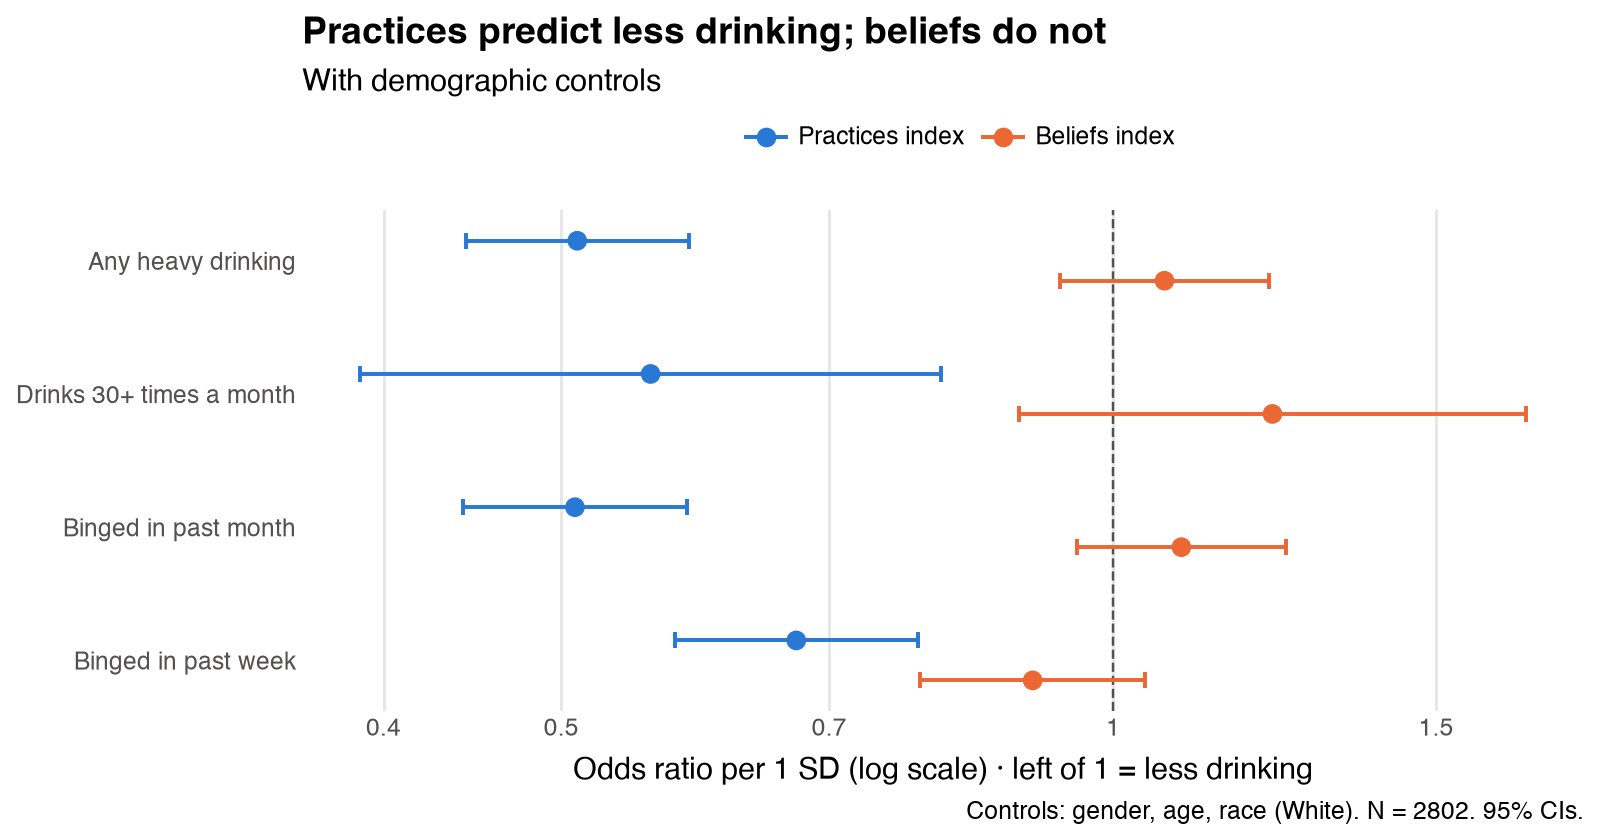

In [137]:
controls = ["female", "age", "white"]

# same sample as the AME tables: everyone with all outcomes, religion items and controls
d = df[outcomes + practices + beliefs + controls].dropna().copy()
z = (d[practices + beliefs] - d[practices + beliefs].mean()) / d[practices + beliefs].std()
d["practice_index"] = z[practices].mean(axis=1)
d["belief_index"]   = z[beliefs].mean(axis=1)

rhs_ctrl = "practice_index + belief_index + " + " + ".join(controls)

rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ {rhs_ctrl}", data=d).fit(disp=0, maxiter=200)
    if not m.mle_retvals["converged"]:
        print(f"Warning: {o} did not converge, so read that row with caution")
    ci = m.conf_int()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab, "OR": np.exp(m.params[v]),
                     "lo": np.exp(ci.loc[v, 0]), "hi": np.exp(ci.loc[v, 1])})
forest_ctrl = pd.DataFrame(rows)

# place rows by hand so the two dots in each row don't overlap
row_order = list(outcome_labels.values())[::-1]                     # top to bottom
forest_ctrl["y"] = forest_ctrl["outcome"].map({lab: i for i, lab in enumerate(row_order)})
forest_ctrl["y"] += np.where(forest_ctrl["predictor"] == "Practices index", 0.15, -0.15)
forest_ctrl["predictor"] = pd.Categorical(forest_ctrl["predictor"], categories=["Practices index", "Beliefs index"])

chart_ctrl = (p9.ggplot(forest_ctrl, p9.aes(x="OR", y="y", color="predictor"))
              + p9.geom_vline(xintercept=1, color=MUTED, linetype="dashed")
              + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0.12, size=0.8)
              + p9.geom_point(size=3)
              + p9.scale_x_log10(breaks=[0.4, 0.5, 0.7, 1, 1.5, 2])
              + p9.scale_y_continuous(breaks=list(range(len(row_order))), labels=row_order)
              + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
              + p9.labs(title="Practices predict less drinking; beliefs do not",
                        subtitle="With demographic controls",
                        x="Odds ratio per 1 SD (log scale) · left of 1 = less drinking", y="", color="",
                        caption=f"Controls: gender, age, race (White). N = {len(d)}. 95% CIs.")
              + base_theme + p9.theme(legend_position="top", figure_size=(8, 4.2),
                                      panel_grid_major_y=p9.element_blank()))
chart_ctrl

FIGURE 6

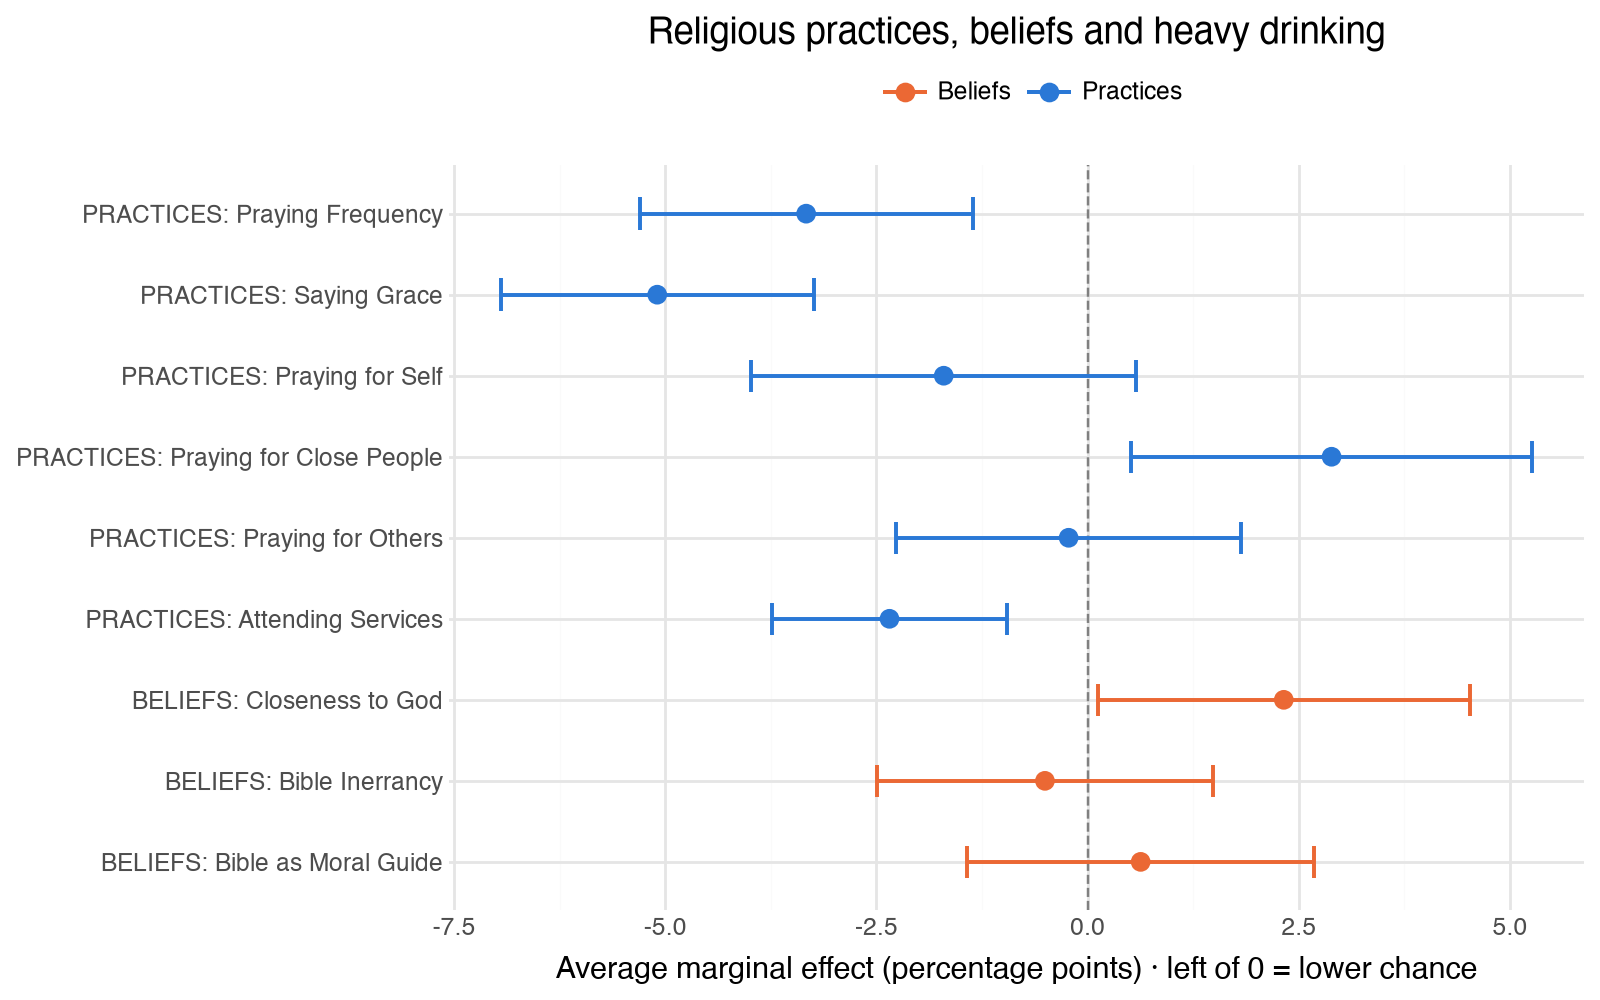

In [136]:
labels = {"pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
          "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
          "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
          "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
          "bible_complete_guide_to_morality": "BELIEFS: Bible as Moral Guide",
          "bible_as_complete_moral_code": "BELIEFS: Bible as Moral Guide"}

USE_CONTROLS = True      # set to False if the drug-use chart was made without controls

items = practices + beliefs
rhs = " + ".join(items)
if USE_CONTROLS:
    rhs += " + " + " + ".join(controls) + " + C(university)"
m = smf.logit(f"alcoholic ~ {rhs}", data=cc).fit(disp=0, maxiter=200)
me = m.get_margeff(at="overall").summary_frame()

ame_alc = pd.DataFrame([{"item": labels[v],
                         "group": "Practices" if v in practices else "Beliefs",
                         "AME": me.loc[v, "dy/dx"] * 100,
                         "lo": me.loc[v, "Conf. Int. Low"] * 100,
                         "hi": me.loc[v, "Cont. Int. Hi."] * 100} for v in items])
ame_alc["item"] = pd.Categorical(ame_alc["item"], categories=[labels[v] for v in items][::-1])   # top to bottom
ame_alc["group"] = pd.Categorical(ame_alc["group"], categories=["Beliefs", "Practices"])

chart_alc_items = (p9.ggplot(ame_alc, p9.aes(x="AME", y="item", color="group"))
                   + p9.geom_vline(xintercept=0, color="grey", linetype="dashed")
                   + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0.4, size=0.8)
                   + p9.geom_point(size=3)
                   + p9.scale_color_manual(values={"Practices": BLUE, "Beliefs": ORANGE})
                   + p9.labs(title="Religious practices, beliefs and heavy drinking",
                             x="Average marginal effect (percentage points) · left of 0 = lower chance",
                             y="", color="")
                   + p9.theme_minimal(base_size=11)
                   + p9.theme(legend_position="top", plot_title=p9.element_text(ha="center"),
                              figure_size=(8, 5)))
chart_alc_items

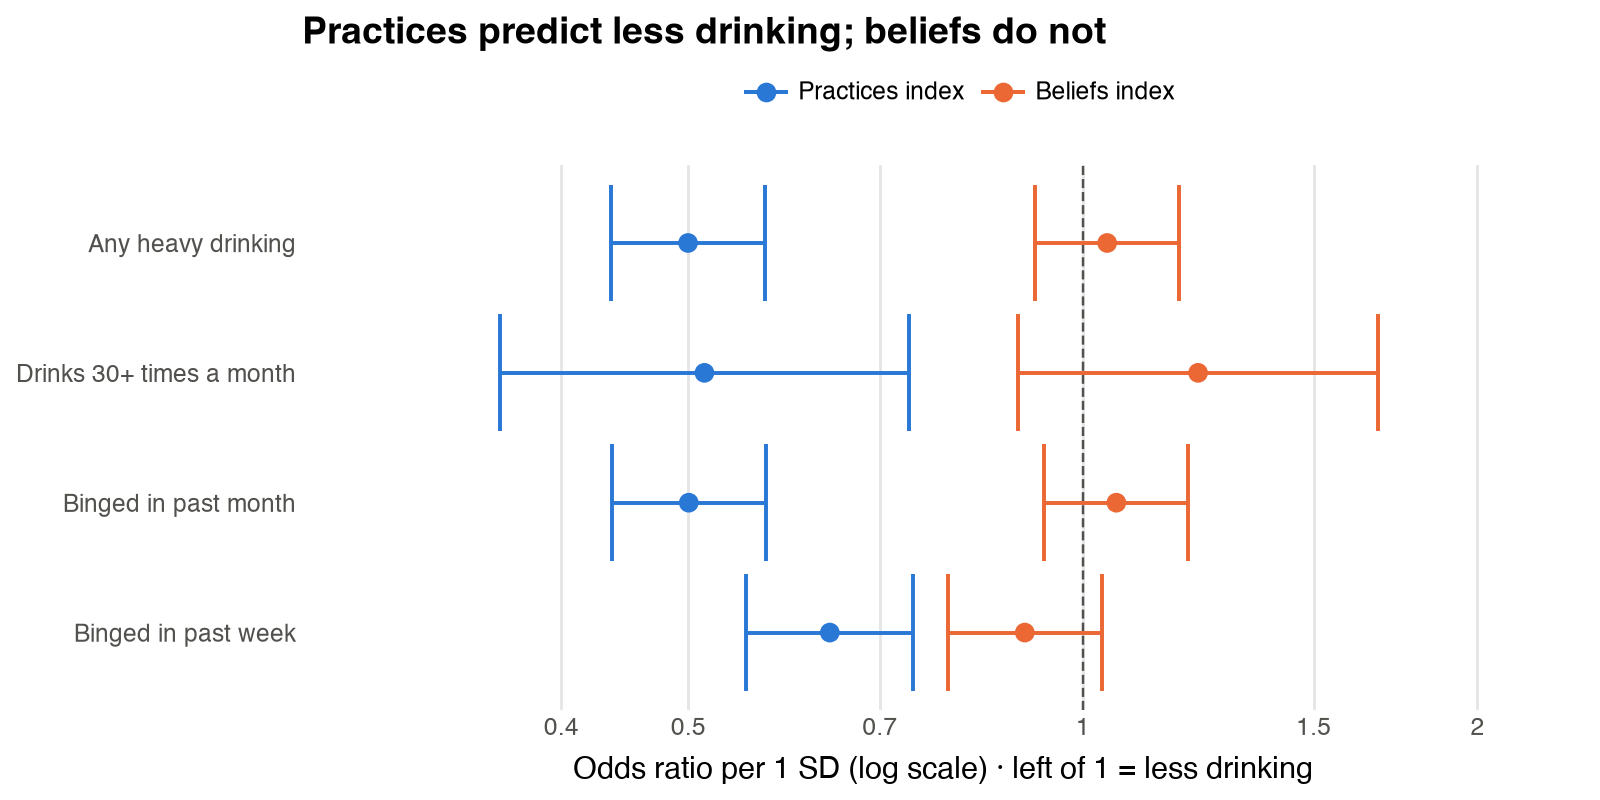

In [99]:
rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0)
    ci = m.conf_int()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab, "OR": np.exp(m.params[v]),
                     "lo": np.exp(ci.loc[v, 0]), "hi": np.exp(ci.loc[v, 1])})
forest = pd.DataFrame(rows)
forest["outcome"] = pd.Categorical(forest["outcome"], categories=list(outcome_labels.values())[::-1])
forest["predictor"] = pd.Categorical(forest["predictor"], categories=["Practices index", "Beliefs index"])
chart1 = (p9.ggplot(forest, p9.aes(x="OR", y="outcome", color="predictor"))
          + p9.geom_vline(xintercept=1, color=MUTED, linetype="dashed")
          + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
          + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
          + p9.scale_x_log10(breaks=[0.4, 0.5, 0.7, 1, 1.5, 2])
          + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
          + p9.labs(title="Practices predict less drinking; beliefs do not",
                    x="Odds ratio per 1 SD (log scale) · left of 1 = less drinking", y="", color="")
          + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart1

FIGURE 7

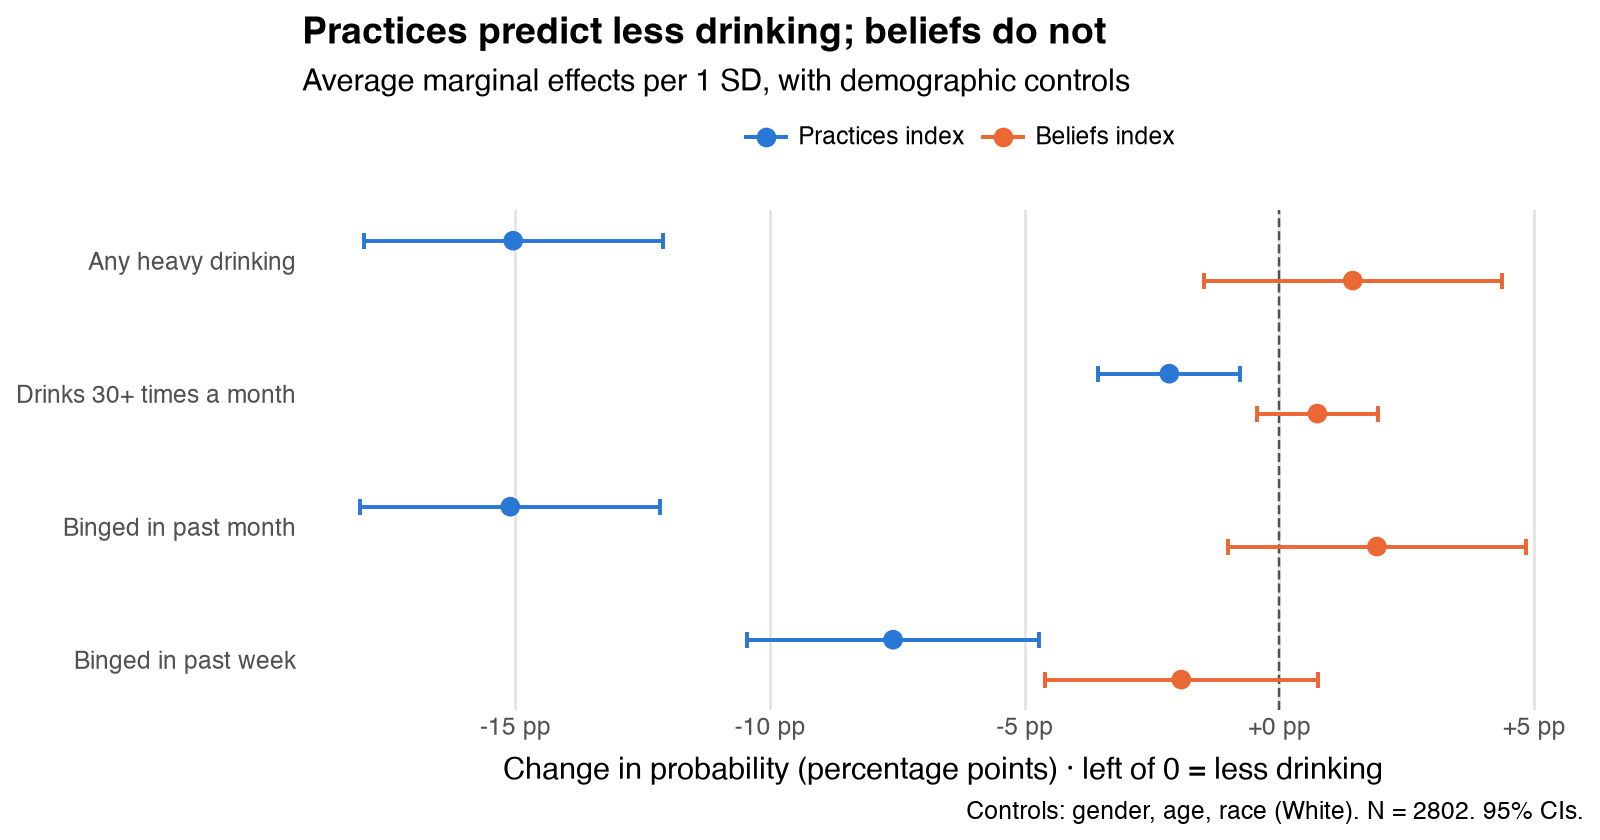

In [138]:
controls = ["female", "age", "white"]

d = df[outcomes + practices + beliefs + controls].dropna().copy()
z = (d[practices + beliefs] - d[practices + beliefs].mean()) / d[practices + beliefs].std()
d["practice_index"] = z[practices].mean(axis=1)
d["belief_index"]   = z[beliefs].mean(axis=1)

rhs_ctrl = "practice_index + belief_index + " + " + ".join(controls)

rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ {rhs_ctrl}", data=d).fit(disp=0, maxiter=200)
    if not m.mle_retvals["converged"]:
        print(f"Warning: {o} did not converge, so read that row with caution")
    me = m.get_margeff(at="overall").summary_frame()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab,
                     "AME": me.loc[v, "dy/dx"] * 100,
                     "lo": me.loc[v, "Conf. Int. Low"] * 100, "hi": me.loc[v, "Cont. Int. Hi."] * 100})
ame_ctrl = pd.DataFrame(rows)

row_order = list(outcome_labels.values())[::-1]                     # top to bottom
ame_ctrl["y"] = ame_ctrl["outcome"].map({lab: i for i, lab in enumerate(row_order)})
ame_ctrl["y"] += np.where(ame_ctrl["predictor"] == "Practices index", 0.15, -0.15)
ame_ctrl["predictor"] = pd.Categorical(ame_ctrl["predictor"], categories=["Practices index", "Beliefs index"])

chart_ame_ctrl = (p9.ggplot(ame_ctrl, p9.aes(x="AME", y="y", color="predictor"))
                  + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
                  + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0.12, size=0.8)
                  + p9.geom_point(size=3)
                  + p9.scale_x_continuous(labels=lambda l: [f"{v:+.0f} pp" for v in l])
                  + p9.scale_y_continuous(breaks=list(range(len(row_order))), labels=row_order)
                  + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
                  + p9.labs(title="Practices predict less drinking; beliefs do not",
                            subtitle="Average marginal effects per 1 SD, with demographic controls",
                            x="Change in probability (percentage points) · left of 0 = less drinking",
                            y="", color="",
                            caption=f"Controls: gender, age, race (White). N = {len(d)}. 95% CIs.")
                  + base_theme + p9.theme(legend_position="top", figure_size=(8, 4.2),
                                          panel_grid_major_y=p9.element_blank()))
chart_ame_ctrl

In [102]:
# --- Forest plot: any heavy drinking, combined indices + individual items ---
nice_items = {"pray_freq": "Praying frequency", "table_grace": "Saying grace", "pray_self": "Praying for self",
              "pray_close": "Praying for close people", "pray_others": "Praying for others",
              "attend_services": "Attending services", "god_close": "Closeness to God",
              "bible_inerrant": "Bible inerrancy",
              "bible_complete_guide_to_morality": "Bible as complete moral guide",
              "bible_as_complete_moral_code": "Bible as complete moral guide"}

d = cc.copy()
items = practices + beliefs
for v in items:
    d[v + "_z"] = (d[v] - d[v].mean()) / d[v].std()                 # standardise: all per 1 SD
d["practice_index"] = d[[v + "_z" for v in practices]].mean(axis=1)
d["belief_index"]

0      -0.343874
1      -1.186559
2      -0.156429
3      -0.624769
4      -0.123933
          ...   
3524   -1.654898
3525   -1.654898
3526   -1.654898
3527   -1.654898
3529   -1.654898
Name: belief_index, Length: 2733, dtype: float64

                                 pray_freq table_grace pray_self pray_close pray_others attend_services god_close bible_inerrant bible_complete_guide_to_morality alcoholic
pray_freq                           1.0***                                                                                                                                 
table_grace                        0.61***      1.0***                                                                                                                     
pray_self                          0.76***     0.51***    1.0***                                                                                                           
pray_close                         0.71***     0.49***   0.79***     1.0***                                                                                                
pray_others                        0.67***     0.48***   0.67***    0.76***      1.0***                                                     

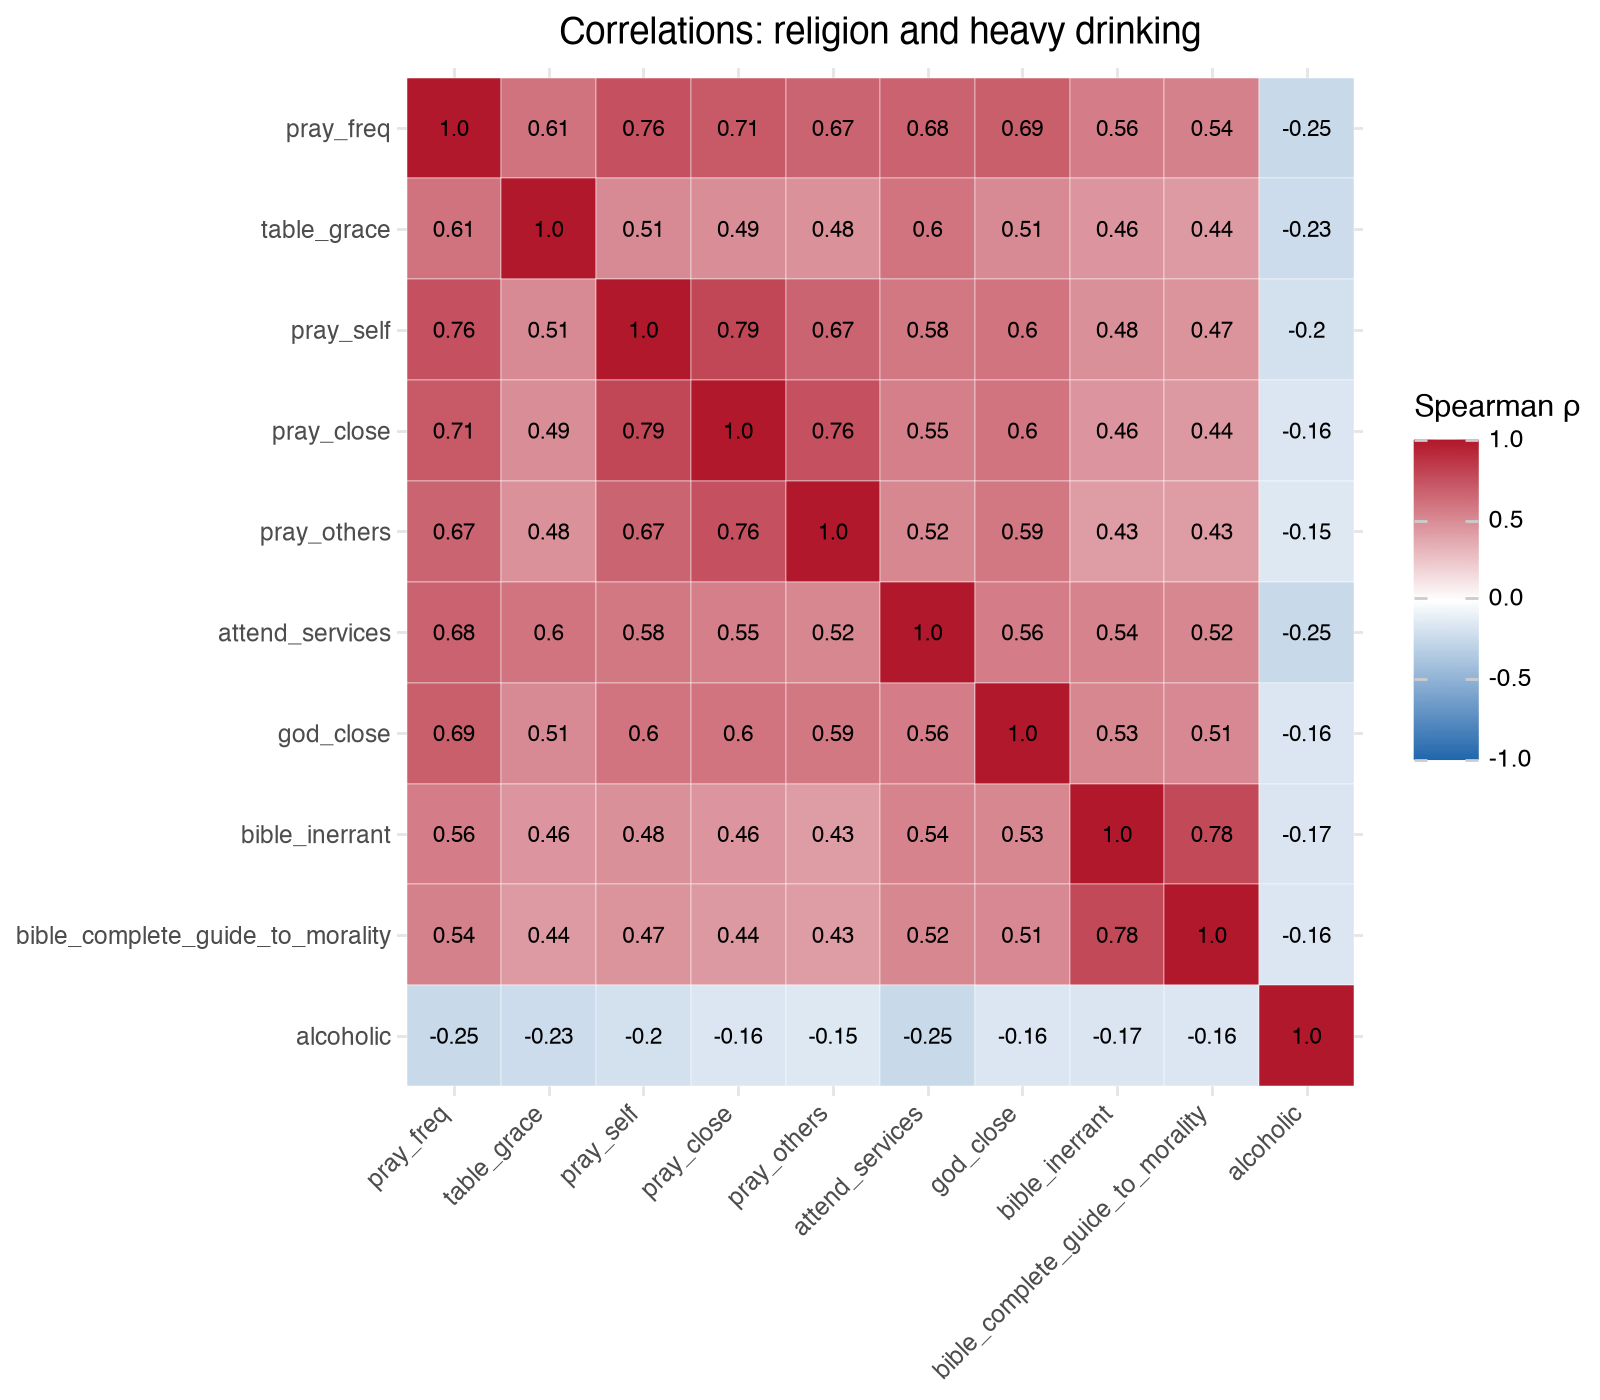

In [139]:
from scipy.stats import spearmanr
import plotnine as p9

cols = practices + beliefs + ["alcoholic"] 

# Spearman correlation (rho) and p-values for every pair
rho, p = spearmanr(ca[cols])
rho = pd.DataFrame(rho, index=cols, columns=cols)
p = pd.DataFrame(p, index=cols, columns=cols)

# Table with stars, same convention as stargazer
stars = p.map(lambda x: "***" if x < 0.01 else "**" if x < 0.05 else "*" if x < 0.1 else "")
table = rho.round(2).astype(str) + stars
table = table.where(np.tril(np.ones(rho.shape, dtype=bool)), "")   # lower triangle only
print(table.to_string())

# Heatmap
long = rho.reset_index().melt(id_vars="index", var_name="var2", value_name="rho").rename(columns={"index": "var1"})
long["var1"] = pd.Categorical(long["var1"], categories=cols)
long["var2"] = pd.Categorical(long["var2"], categories=cols[::-1])
heat = (p9.ggplot(long, p9.aes("var1", "var2", fill="rho"))
        + p9.geom_tile(color="white")
        + p9.geom_text(p9.aes(label="rho.round(2)"), size=8)
        + p9.scale_fill_gradient2(low="#2166ac", mid="white", high="#b2182b", midpoint=0, limits=(-1, 1))
        + p9.labs(x="", y="", fill="Spearman ρ", title="Correlations: religion and heavy drinking")
        + p9.theme_minimal()
        + p9.theme(axis_text_x=p9.element_text(rotation=45, ha="right"), figure_size=(8, 7)))
heat

Controls: Gender, Race, Age, Parents' Education

In [ ]:
# Control variables
df["female"]    = np.where(df["V3"].isna(), np.nan, (df["V3"] == 2).astype(int))     # V3: 1 = Male, 2 = Female
df["age"]       = df["V1"]                                                            # V1: 1 = 18 or under ... 6 = 23 or older
df["white"]     = np.where(df["V2"].isna(), np.nan, (df["V2"] == 1).astype(int))     # V2: 1 = White, 2-5 = other groups
df["mother_edu"] = df["V5"].where(df["V5"].between(1, 8))                             # V5: 1-8 scale; code 9 has no label, so set to missing
# University: asked in two versions of the survey (V91 or V92), combined into one variable
df["university"] = np.where(df["V91"].notna(), "A" + df["V91"].astype("Int64").astype(str),
                            np.where(df["V92"].notna(), "B" + df["V92"].astype("Int64").astype(str), np.nan))
df.loc[df["university"].isin(["nan", "A<NA>", "B<NA>"]), "university"] = np.nan

controls = ["female", "age", "white", "mother_edu"]

# One common sample: everyone with all outcomes, religion items AND controls
cc = df[outcomes + practices + beliefs + controls + ["university"]].dropna().copy()
print("N =", len(cc))

z = (cc[practices + beliefs] - cc[practices + beliefs].mean()) / cc[practices + beliefs].std()
cc["practice_index"] = z[practices].mean(axis=1)
cc["belief_index"]   = z[beliefs].mean(axis=1)

rhs_no_ctrl = "practice_index + belief_index"
rhs_ctrl    = "practice_index + belief_index + " + " + ".join(controls)
rhs_ctrl_uni = rhs_ctrl + " + C(university)"                # adds a separate intercept for each university

N = 2757


In [ ]:
from statsmodels.imputation.mice import MICEData
from scipy.stats import norm

items = practices + beliefs

def index_ame(data, rhs_extra=""):
    """Build the two indices on this data, fit the logit, return AMEs (pp) and their SEs for both indices."""
    d = data.copy()
    z = (d[items] - d[items].mean()) / d[items].std()
    d["practice_index"] = z[practices].mean(axis=1)
    d["belief_index"]   = z[beliefs].mean(axis=1)
    m = smf.logit(f"alcoholic ~ practice_index + belief_index + {' + '.join(controls)} + C(university){rhs_extra}", data=d).fit(disp=0)
    me = m.get_margeff(at="overall").summary_frame().loc[["practice_index", "belief_index"]]
    return me["dy/dx"] * 100, me["Std. Err."] * 100, len(d)

# Keep everyone whose drinking outcome is known (we don't make up the outcome itself)
base = df[df["alcoholic"].notna()][["alcoholic"] + items + controls + ["university"]].copy()

# --- Approach 1: complete cases (what we have been doing) ---
est_cc, se_cc, n_cc = index_ame(base.dropna())

# --- Approach 2: missing-indicator ---
# Fill missing attendance with 0 ("Never") and add a flag, since most who skipped it never pray
mi_data = base.copy()
mi_data["attend_missing"] = mi_data["attend_services"].isna().astype(int)
mi_data["attend_services"] = mi_data["attend_services"].fillna(0)
est_ind, se_ind, n_ind = index_ame(mi_data.dropna(), " + attend_missing")

# --- Approach 3: multiple imputation (MICE) ---
# Fill each missing answer using the student's other answers, 20 times, then average the results (Rubin's rules)
imp = base[["alcoholic"] + items + controls].copy()
uni_dummies = pd.get_dummies(base["university"], prefix="uni", drop_first=True).astype(float)
imp = pd.concat([imp, uni_dummies], axis=1)

mice = MICEData(imp)                       # predictive mean matching: only fills in values that real students gave
ests, ses = [], []
for i in range(20):
    mice.update_all(5)
    filled = mice.data.copy()
    filled["university"] = base["university"].values
    e, s, n_mi = index_ame(filled)
    ests.append(e); ses.append(s)
ests, ses = pd.DataFrame(ests), pd.DataFrame(ses)
est_mi = ests.mean()
se_mi = np.sqrt((ses ** 2).mean() + (1 + 1 / len(ests)) * ests.var())     # Rubin's rules

def fmt(e, s):
    p = 2 * (1 - norm.cdf(abs(e / s)))
    return f"{e:.1f}" + ("***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else "")

compare = pd.DataFrame({
    "Complete cases":      [fmt(est_cc[v], se_cc[v]) for v in est_cc.index] + [n_cc],
    "Missing indicator":   [fmt(est_ind[v], se_ind[v]) for v in est_ind.index] + [n_ind],
    "Multiple imputation": [fmt(est_mi[v], se_mi[v]) for v in est_mi.index] + [n_mi],
}, index=["Practices index (pp per 1 SD)", "Beliefs index (pp per 1 SD)", "N"])
print("Any heavy drinking: average marginal effects, with demographic and university controls")
display(compare)

Any heavy drinking: average marginal effects, with demographic and university controls


,Complete cases,Missing indicator,Multiple imputation
Practices index (pp per 1 SD),-11.7***,-12.0***,-11.5***
Beliefs index (pp per 1 SD),0.6,1.2,1.6
N,2901,3231,3458


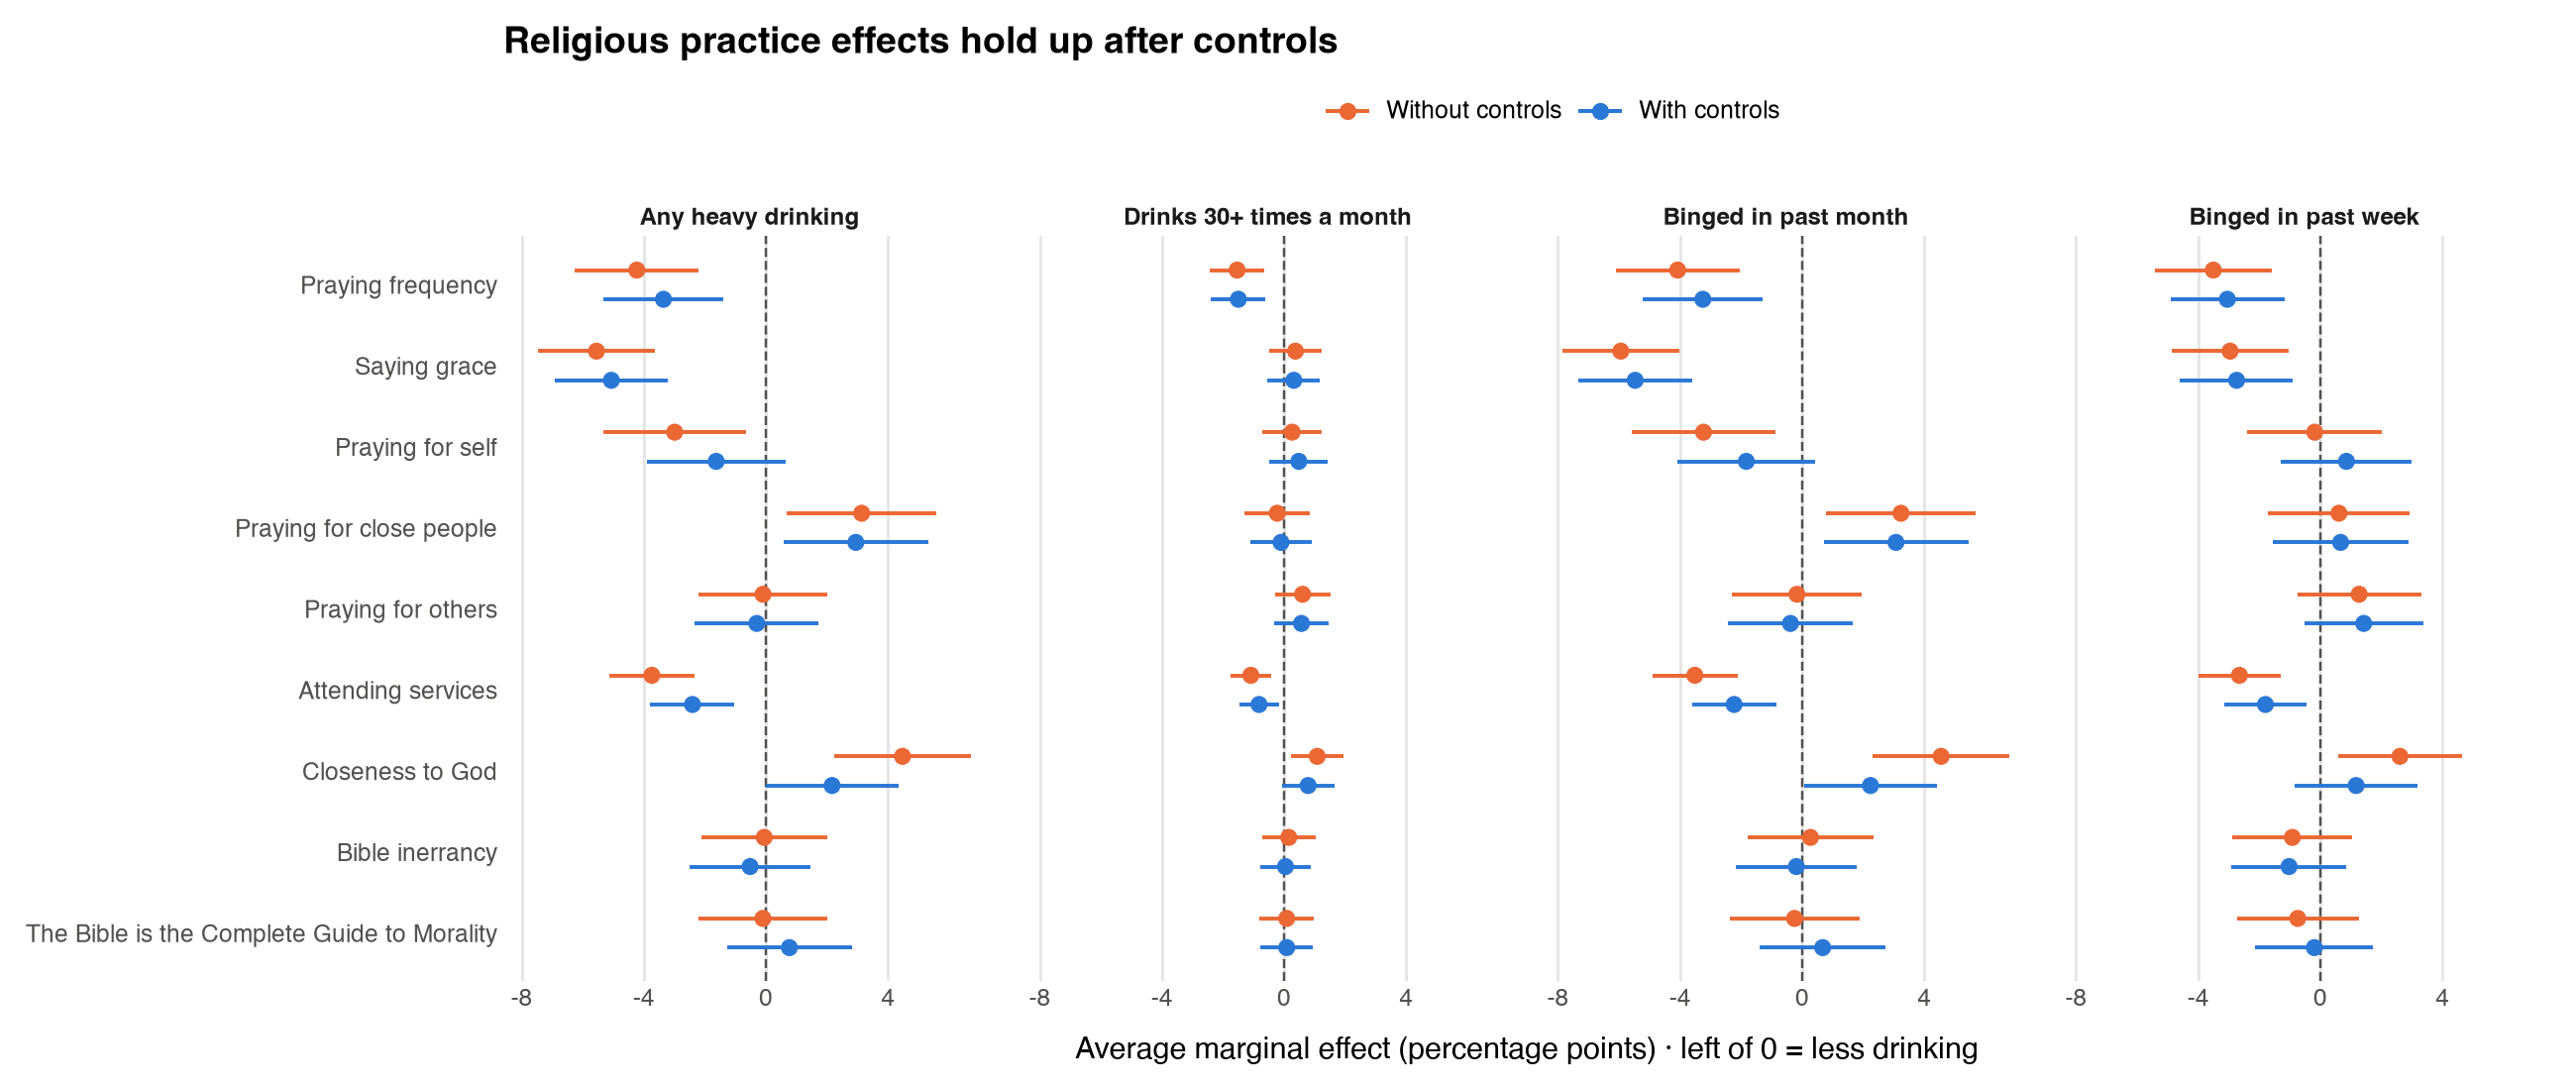

In [ ]:
# Average marginal effects (percentage points) for the 8 religion items, without vs with controls
rows = []
for o, i in zip(outcomes, range(0, 8, 2)):
    for version, m in [("Without controls", pairs[i]), ("With controls", pairs[i + 1])]:
        me = m.get_margeff(at="overall").summary_frame()
        for v in practices + beliefs:
            rows.append({"outcome": outcome_labels[o], "item": item_labels[v], "version": version,
                         "AME": me.loc[v, "dy/dx"] * 100,
                         "lo": me.loc[v, "Conf. Int. Low"] * 100, "hi": me.loc[v, "Cont. Int. Hi."] * 100})
cmp = pd.DataFrame(rows)
cmp["outcome"] = pd.Categorical(cmp["outcome"], categories=list(outcome_labels.values()))
item_order = [item_labels[v] for v in practices + beliefs][::-1]           # top to bottom as in the tables
cmp["y"] = cmp["item"].map({lab: i for i, lab in enumerate(item_order)})
cmp["y"] += np.where(cmp["version"] == "Without controls", 0.18, -0.18)     # nudge the two versions apart
cmp["version"] = pd.Categorical(cmp["version"], categories=["Without controls", "With controls"])

chart_cmp = (p9.ggplot(cmp, p9.aes(x="AME", y="y", color="version"))
             + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
             + p9.geom_segment(p9.aes(x="lo", xend="hi", yend="y"), size=0.8)
             + p9.geom_point(size=2.5)
             + p9.facet_wrap("~outcome", ncol=4)
             + p9.scale_y_continuous(breaks=list(range(len(item_order))), labels=item_order)
             + p9.scale_color_manual(values={"Without controls": ORANGE, "With controls": BLUE})
             + p9.labs(title="Religious practice effects hold up after controls",
                       x="Average marginal effect (percentage points) · left of 0 = less drinking", y="", color="")
             + base_theme + p9.theme(legend_position="top", figure_size=(13, 5.5),
                                     strip_text=p9.element_text(weight="bold", ha="center")))
chart_cmp

PCA Stuff

In [ ]:
cols = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services", "god_close", "bible_inerrant", "bible_complete_guide_to_morality"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,pray_freq,table_grace,pray_self,pray_close,pray_others,attend_services,god_close,bible_inerrant,bible_complete_guide_to_morality
count,3034.0,3034.0,3034.0,3034.0,3034.0,3034.0,3034.0,3034.0,3034.0
mean,2.4,1.4,2.0,2.1,1.6,2.7,3.5,3.0,3.1
std,1.7,1.2,1.4,1.4,1.3,1.8,1.2,1.4,1.4
min,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
25%,1.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0,2.0
50%,3.0,1.0,2.0,2.0,1.0,2.0,4.0,3.0,3.0
75%,4.0,2.0,3.0,4.0,2.0,5.0,4.0,4.0,4.0
max,5.0,4.0,4.0,4.0,4.0,5.0,5.0,5.0,5.0


In [ ]:
print(cols)

['pray_freq', 'table_grace', 'pray_self', 'pray_close', 'pray_others', 'attend_services', 'god_close', 'bible_inerrant', 'bible_complete_guide_to_morality']


In [ ]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

pc_names = [f"PC{i+1}" for i in range(pca.n_components_)]   # adapts to however many items are in cols
prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=pc_names).T.round(3))

# loadings: which items drive each component
loadings = pd.DataFrame(pca.components_.T, index=cols, columns=pc_names).round(2)
print(loadings.iloc[:, :3])   # first 3 components are usually enough to look at

                          PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
Standard deviation      2.340  1.011  0.828  0.663  0.632  0.596  0.475   
Proportion of variance  0.608  0.114  0.076  0.049  0.044  0.039  0.025   
Cumulative proportion   0.608  0.722  0.798  0.847  0.891  0.931  0.956   

                          PC8    PC9  
Standard deviation      0.465  0.426  
Proportion of variance  0.024  0.020  
Cumulative proportion   0.980  1.000  
                                   PC1   PC2   PC3
pray_freq                         0.38 -0.10  0.12
table_grace                       0.29  0.05  0.74
pray_self                         0.36 -0.28 -0.12
pray_close                        0.35 -0.36 -0.23
pray_others                       0.32 -0.39 -0.26
attend_services                   0.33  0.10  0.40
god_close                         0.34  0.00 -0.08
bible_inerrant                    0.31  0.55 -0.24
bible_complete_guide_to_morality  0.30  0.56 -0.28


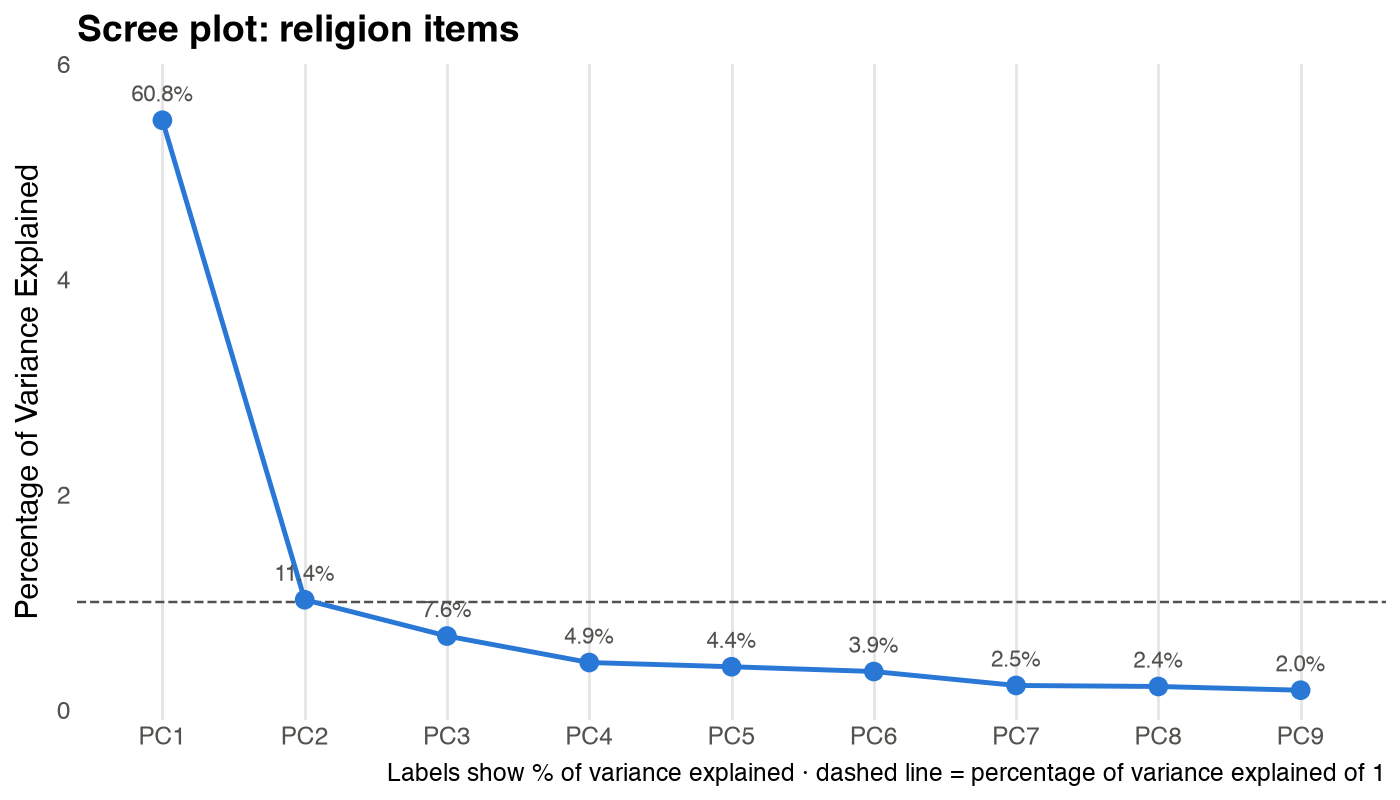

In [ ]:
scree = pd.DataFrame({
    "component": pc_names,
    "eigenvalue": pca.explained_variance_,
    "prop": pca.explained_variance_ratio_,
})
scree["component"] = pd.Categorical(scree["component"], categories=pc_names)   # keep PC1..PC9 in order
scree["label"] = (scree["prop"] * 100).round(1).astype(str) + "%"

chart_scree = (p9.ggplot(scree, p9.aes(x="component", y="eigenvalue", group=1))
               + p9.geom_hline(yintercept=1, color=MUTED, linetype="dashed")      # Kaiser rule: keep eigenvalues > 1
               + p9.geom_line(color=BLUE, size=1)
               + p9.geom_point(color=BLUE, size=3)
               + p9.geom_text(p9.aes(label="label"), nudge_y=0.25, size=8, color=MUTED)
               + p9.labs(title="Scree plot: religion items",
                         x="", y="Percentage of Variance Explained", caption="Labels show % of variance explained · dashed line = percentage of variance explained of 1")
               + base_theme + p9.theme(figure_size=(7, 4)))
chart_scree

In [132]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

items = practices + beliefs
pca = PCA().fit(StandardScaler().fit_transform(d[items]))
scores = pca.transform(StandardScaler().fit_transform(d[items]))
d["PC1"], d["PC2"] = scores[:, 0] / scores[:, 0].std(), scores[:, 1] / scores[:, 1].std()
if d["PC1"].corr(d["pray_freq"]) < 0:      # make higher PC1 = more religious
    d["PC1"] = -d["PC1"]

print(pd.DataFrame(pca.components_[:2].T, index=items, columns=["PC1", "PC2"]).round(2))  # loadings
m_pc = smf.logit(f"alcoholic ~ PC1 + PC2 + {ctrl}", data=d).fit(disp=0)
print(m_pc.get_margeff(at="overall").summary_frame().loc[["PC1", "PC2"], ["dy/dx", "Pr(>|z|)"]].round(3))

                                   PC1   PC2
pray_freq                         0.38 -0.10
table_grace                       0.29  0.07
pray_self                         0.36 -0.29
pray_close                        0.35 -0.37
pray_others                       0.32 -0.39
attend_services                   0.33  0.11
god_close                         0.34  0.00
bible_inerrant                    0.31  0.54
bible_complete_guide_to_morality  0.30  0.56
     dy/dx  Pr(>|z|)
PC1 -0.109     0.000
PC2 -0.012     0.168


#CONTROLS

In [134]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

items = practices + beliefs

# PCA scores on the same sample as the main models (d), standardised so 1 unit = 1 SD
X = StandardScaler().fit_transform(d[items])
pca = PCA().fit(X)
scores = pca.transform(X)
d["PC1"] = scores[:, 0] / scores[:, 0].std()
d["PC2"] = scores[:, 1] / scores[:, 1].std()
if d["PC1"].corr(d["pray_freq"]) < 0:          # make higher PC1 = more religious
    d["PC1"] = -d["PC1"]

specs = {
    "Main: indices":   ("practice_index + belief_index", {"practice_index": "Practices index", "belief_index": "Beliefs index"}),
    "Robust: PC1":     ("PC1",                           {"PC1": "PC1 (general religiosity)"}),
    "Robust: PC1+PC2": ("PC1 + PC2",                     {"PC1": "PC1 (general religiosity)", "PC2": "PC2 (scripture vs. private prayer)"}),
}

rows = []
for spec, (rhs, names) in specs.items():
    for o in outcomes:
        m = smf.logit(f"{o} ~ {rhs} + {ctrl}", data=d).fit(disp=0, maxiter=200)
        me = m.get_margeff(at="overall").summary_frame()
        for v, lab in names.items():
            rows.append({"Model": spec, "Variable": lab, "outcome": outcome_labels[o],
                         "cell": f"{me.loc[v, 'dy/dx'] * 100:.1f}{stars(me.loc[v, 'Pr(>|z|)'])}"})
        rows.append({"Model": spec, "Variable": "Pseudo R²", "outcome": outcome_labels[o],
                     "cell": f"{m.prsquared:.3f}"})

var_order = ["Practices index", "Beliefs index", "PC1 (general religiosity)",
             "PC2 (scripture vs. private prayer)", "Pseudo R²"]
robust = (pd.DataFrame(rows)
          .pivot_table(index=["Model", "Variable"], columns="outcome", values="cell", aggfunc="first")
          [list(outcome_labels.values())])
robust = robust.reindex(sorted(robust.index, key=lambda k: (list(specs).index(k[0]), var_order.index(k[1]))))
print(f"Robustness check: average marginal effects (percentage points per 1 SD), N = {len(d)}")
print(f"PC1 explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance; PC2 {pca.explained_variance_ratio_[1]*100:.1f}%")
display(robust)

Robustness check: average marginal effects (percentage points per 1 SD), N = 2802
PC1 explains 61.1% of variance; PC2 11.3%


outcome                                            Any heavy drinking  \
Model           Variable                                                
Main: indices   Practices index                              -15.0***   
                Beliefs index                                     1.4   
                Pseudo R²                                       0.080   
Robust: PC1     PC1 (general religiosity)                    -10.8***   
                Pseudo R²                                       0.075   
Robust: PC1+PC2 PC1 (general religiosity)                    -10.9***   
                PC2 (scripture vs. private prayer)               -1.2   
                Pseudo R²                                       0.075   

outcome                                            Drinks 30+ times a month  \
Model           Variable                                                      
Main: indices   Practices index                                     -2.2***   
                Beliefs index                                           0.7   
                Pseudo R²                                             0.057   
Robust: PC1     PC1 (general religiosity)                           -1.1***   
                Pseudo R²                                             0.053   
Robust: PC1+PC2 PC1 (general religiosity)                           -1.1***   
                PC2 (scripture vs. private prayer)                     -0.1   
                Pseudo R²                                             0.053   

outcome                                            Binged in past month  \
Model           Variable                                                  
Main: indices   Practices index                                -15.1***   
                Beliefs index                                       1.9   
                Pseudo R²                                         0.079   
Robust: PC1     PC1 (general religiosity)                      -10.5***   
                Pseudo R²                                         0.074   
Robust: PC1+PC2 PC1 (general religiosity)                      -10.5***   
                PC2 (scripture vs. private prayer)                 -1.0   
                Pseudo R²                                         0.074   

outcome                                            Binged in past week  
Model           Variable                                                
Main: indices   Practices index                                -7.6***  
                Beliefs index                                     -1.9  
                Pseudo R²                                        0.071  
Robust: PC1     PC1 (general religiosity)                      -7.4***  
                Pseudo R²                                        0.070  
Robust: PC1+PC2 PC1 (general religiosity)                      -7.4***  
                PC2 (scripture vs. private prayer)             -2.7***  
                Pseudo R²                                        0.073

In [130]:
import statsmodels.formula.api as smf

work['PC1'] = pca.transform(X)[:, 0]

In [131]:
extra_map = {
    'V74': 'drink_freq',            # frequency of drinking (1 = more than 30 drinks a month)
    'V75': 'month_more_than_5_drinks_at_once',           # drinking more than 5 drinks on one occasion in the past month
    'V76': 'week_more_than_5_drinks_at_once',     # drinking more than 5 drinks on one occasion in the past week
    'V3':  'gender_code',               # 1 = male, 2 = female
    'V2':  'race_code',                 # 1 = White, 2 = Black, 3 = Hispanic, 4 = Asian/Pacific Islander, 5 = Other
}
for old, new in extra_map.items():
    work[new] = pd.to_numeric(raw_df.loc[work.index, old], errors='coerce')


In [ ]:
drink_items = ["drink_freq", "month_more_than_5_drinks_at_once", "week_more_than_5_drinks_at_once"]

alcoholic = ((df["drink_freq"] == 4) |                            # drinks 30+ times a month
             (df["month_more_than_5_drinks_at_once"] == 1) |      # binged in past month (1 = Yes)
             (df["week_more_than_5_drinks_at_once"] == 1))        # binged in past week  (1 = Yes)

# missing only if the student skipped ALL three drinking questions
df["alcoholic"] = np.where(df[drink_items].isna().all(axis=1), np.nan, alcoholic.astype(float))
print(df["alcoholic"].value_counts(dropna=False))

alcoholic
1.0    1734
0.0    1724
NaN      72
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. PC1 religiosity score for every student who answered all the religion items
pca_df = df[cols].dropna()                       # cols = your religion items only
X = StandardScaler().fit_transform(pca_df)
pca = PCA().fit(X)
pc1 = pca.transform(X)[:, 0]

# PCA picks the sign arbitrarily: flip it if needed so that higher = more religious
if np.corrcoef(pc1, pca_df["pray_freq"])[0, 1] < 0:
    pc1 = -pc1
pc1 = (pc1 - pc1.mean()) / pc1.std()             # standardise: coefficient = effect of 1 SD more religiosity
df["PC1"] = pd.Series(pc1, index=pca_df.index)   # students missing an item get NaN

# 2. Gender (V3: 1 = Male, 2 = Female)
df["sex_woman"] = pd.Categorical(
    np.where(df["V3"].isna(), None, np.where(df["V3"] == 2, "Woman", "Man")),
    categories=["Man", "Woman"]                  # first category = reference
)

# 3. Race (V2): take the text labels straight from the Stata file; code 1 (White) comes first = reference
race = pd.read_stata("chrisu.DTA", columns=["V2"])["V2"]
df["race_cat"] = pd.Categorical(race, categories=race.cat.categories)
print(df["race_cat"].value_counts(dropna=False))

# 4. Keep respondents with complete data on everything in the model
model_df = df.dropna(subset=["alcoholic", "PC1", "sex_woman", "race_cat"]).copy()
print("N in model:", len(model_df))

# 5. Logit
logit_alc = smf.logit("alcoholic ~ PC1 + sex_woman + race_cat", data=model_df).fit(maxiter=100)
print(logit_alc.summary())
print(np.exp(logit_alc.params).round(3))          # odds ratios

race_cat
White                        2355
Asian or Pacific Islander     362
Black                         323
Hispanic                      315
Other                         142
NaN                            33
Name: count, dtype: int64
N in model: 2953
Optimization terminated successfully.
         Current function value: 0.636450
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              alcoholic   No. Observations:                 2953
Model:                          Logit   Df Residuals:                     2946
Method:                           MLE   Df Model:                            6
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.08065
Time:                        19:54:06   Log-Likelihood:                -1879.4
converged:                       True   LL-Null:                       -2044.3
Covariance Type:            nonrobust   LLR p-value:                 3.458e-68
          

In [ ]:
drink_items = ["drink_freq", "month_more_than_5_drinks_at_once", "week_more_than_5_drinks_at_once"]

alcoholic = ((df["drink_freq"] == 4) |                            # drinks 30+ times a month
             (df["month_more_than_5_drinks_at_once"] == 1) |      # binged in past month (1 = Yes)
             (df["week_more_than_5_drinks_at_once"] == 1))        # binged in past week  (1 = Yes)
df["alcoholic"] = np.where(df[drink_items].isna().all(axis=1), np.nan, alcoholic.astype(float))

# rebuild model_df from df
model_df = df.dropna(subset=["alcoholic", "PC1", "sex_woman", "race_cat"]).copy()
print("N in model:", len(model_df))
print("Share coded alcoholic:", round(model_df["alcoholic"].mean(), 3))

logit_alc = smf.logit("alcoholic ~ PC1 + sex_woman + race_cat", data=model_df).fit()
print(logit_alc.summary())

N in model: 2953
Share coded alcoholic: 0.479
Optimization terminated successfully.
         Current function value: 0.636450
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              alcoholic   No. Observations:                 2953
Model:                          Logit   Df Residuals:                     2946
Method:                           MLE   Df Model:                            6
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.08065
Time:                        19:57:50   Log-Likelihood:                -1879.4
converged:                       True   LL-Null:                       -2044.3
Covariance Type:            nonrobust   LLR p-value:                 3.458e-68
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercep

In [ ]:
import statsmodels.api as sm

In [ ]:


# 1. Is PC1 basically your existing religiosity index?
tmp = df[["PC1"]].join(ca["religiosity_index"], how="inner")
print("r(PC1, religiosity_index) =", round(tmp.corr().iloc[0, 1], 3))

# 2. How bad is the collinearity among the raw items? (VIF > 5 is a common warning sign)
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(df[practices + beliefs].dropna())
print(pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=practices + beliefs).round(2))

r(PC1, religiosity_index) = 1.0
pray_freq                           3.68
table_grace                         1.74
pray_self                           3.33
pray_close                          3.68
pray_others                         2.36
attend_services                     2.17
god_close                           2.23
bible_inerrant                      2.85
bible_complete_guide_to_morality    2.72
dtype: float64


Figure 6

In [129]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# ---------- 1. Load and rename ----------
df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self", "V28": "pray_close",
    "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant", "V41": "bible_complete_guide_to_morality",
    "V74": "drink_freq", "V75": "binge_month_raw", "V76": "binge_week_raw",
})
df["god_close"] = 6 - df["god_close"]          # higher = closer to God

# ---------- 2. Outcomes (missing stays missing) ----------
def flag(col, condition):
    return np.where(df[col].isna(), np.nan, condition.astype(int))

df["drinks_30_plus"] = flag("drink_freq", df["drink_freq"] == 4)
df["binge_month"]    = flag("binge_month_raw", df["binge_month_raw"] == 1)
df["binge_week"]     = flag("binge_week_raw", df["binge_week_raw"] == 1)
three = ["drinks_30_plus", "binge_month", "binge_week"]
df["alcoholic"] = np.where(df[three].isna().any(axis=1), np.nan, df[three].max(axis=1))

# ---------- 3. Controls ----------
df["female"] = np.where(df["V3"].isna(), np.nan, (df["V3"] == 2).astype(int))   # 2 = Female
df["age"]    = df["V1"]
df["white"]  = np.where(df["V2"].isna(), np.nan, (df["V2"] == 1).astype(int))   # 1 = White

# ---------- 4. Lists and labels ----------
outcomes  = ["alcoholic", "drinks_30_plus", "binge_month", "binge_week"]
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs   = ["god_close", "bible_inerrant", "bible_complete_guide_to_morality"]
controls  = ["female", "age", "white"]

outcome_labels = {"alcoholic": "Any heavy drinking", "drinks_30_plus": "Drinks 30+ times a month",
                  "binge_month": "Binged in past month", "binge_week": "Binged in past week"}
item_labels = {"pray_freq": "PRACTICES: Praying frequency", "table_grace": "PRACTICES: Saying grace", "pray_self": "PRACTICES: Praying for self",
               "pray_close": "PRACTICES: Praying for close people", "pray_others": "PRACTICES: Praying for others",
               "attend_services": "PRACTICES: Attending services", "god_close": "BELIEFS: Closeness to God",
               "bible_inerrant": "BELIEFS: Bible inerrancy",
               "bible_complete_guide_to_morality": "BELIEFS: The Bible is the Complete Guide to Morality"}

# ---------- 5. Common sample + indices ----------
d = df[outcomes + practices + beliefs + controls].dropna().copy()
print("N =", len(d))
z = (d[practices + beliefs] - d[practices + beliefs].mean()) / d[practices + beliefs].std()
d["practice_index"] = z[practices].mean(axis=1)
d["belief_index"]   = z[beliefs].mean(axis=1)
ctrl = " + ".join(controls)

# ---------- 6. Average marginal effects ----------
def ame_table(formula_rhs, names):
    rows = []
    for o in outcomes:
        m = smf.logit(f"{o} ~ {formula_rhs} + {ctrl}", data=d).fit(disp=0, maxiter=200)
        if not m.mle_retvals["converged"]:
            print(f"  Warning: {outcome_labels[o]} did not converge")
        me = m.get_margeff(at="overall").summary_frame()
        for v in names:
            rows.append({"outcome": outcome_labels[o], "variable": names[v],
                         "AME": me.loc[v, "dy/dx"], "p": me.loc[v, "Pr(>|z|)"]})
    return pd.DataFrame(rows)

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def to_wide(t, order):
    t = t.assign(cell=(t["AME"] * 100).round(1).astype(str) + t["p"].map(stars))
    return t.pivot(index="variable", columns="outcome", values="cell").loc[order, list(outcome_labels.values())]

item_names = {v: item_labels[v] for v in practices + beliefs}
print("Average marginal effects, percentage points (item model, with controls)")
display(to_wide(ame_table(" + ".join(practices + beliefs), item_names), list(item_names.values())))

index_names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)"}
print("Average marginal effects, percentage points (index model, with controls)")
display(to_wide(ame_table("practice_index + belief_index", index_names), list(index_names.values())))

N = 2802
Average marginal effects, percentage points (item model, with controls)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
PRACTICES: Praying frequency,-4.8***,-1.6***,-4.7***,-4.0***
PRACTICES: Saying grace,-5.6***,0.2,-6.0***,-3.1***
PRACTICES: Praying for self,-1.4,0.4,-1.5,1.1
PRACTICES: Praying for close people,3.2***,-0.1,3.3***,0.8
PRACTICES: Praying for others,-0.1,0.7,-0.1,1.6
PRACTICES: Attending services,-3.7***,-1.0***,-3.5***,-2.7***
BELIEFS: Closeness to God,4.1***,1.0**,4.1***,2.3**
BELIEFS: Bible inerrancy,0.1,0.2,0.3,-0.6
BELIEFS: The Bible is the Complete Guide to Morality,0.3,0.0,0.2,-0.6


Average marginal effects, percentage points (index model, with controls)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
Practices index (per 1 SD),-15.0***,-2.2***,-15.1***,-7.6***
Beliefs index (per 1 SD),1.4,0.7,1.9,-1.9
